# 7. Benchmarks

In this notebook, we compare this planner with five sampling-based planners,
on three scenes, with the same measurement code on both sides.

**The baseline runs are read, not re-run.** Four of the five planners compared
here are anytime: they explore for as long as their time budget allows, so a
differently loaded machine grows a different tree and returns a different path.
RRT stops at its first solution. The campaigns in `data/campaigns/` hold one
such run, and this notebook reads them. The figures below are thus a fixed
comparison, not a new sample of the same distribution.
`shfm.campaigns` holds the code that produced them, and
`scripts/regenerate_campaigns.py` re-runs it.

Our paths are solved at every execution, with the settings of the comparisons:
transition costs $k_1 = 2$, $k_2 = 3$, the reference speed coefficients, a
steering saturation of 0.5 rad, the start mode left free, the PastSeed
criterion of the backtracking delayed to 128 steps and the clearance term
capped at the vehicle length. Each path is cleaned of the extraction chatter
and its start closed on the requested pose before it is drawn or measured
(notebook 5 describes both steps). Section 4 solves one problem again to see
how far two solves are apart.

The baselines planned with the envelopes their campaigns were given, 4.133 m
by 0.700 m on these scenes, where this package declares a 3.649 m by 0.700 m
vehicle (see `data/footprints/README.md`).

This notebook solves and draws the trajectories; notebook 8 measures them. It
writes the statistics of our paths in `runs/`, where that notebook reads them.

**Summary**

1. [The three scenes](#1)
2. [Solving them](#2)
3. [Trajectories](#3)
4. [Solving again](#4)
5. [What notebook 8 picks up](#5)

In [1]:
import sys, os, time, logging
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import cupy as cp
import matplotlib.pyplot as plt

from shfm import DEFAULT_VEHICLE, from_benchmark_run, Planner, REFERENCE_COEFFICIENTS
from shfm import benchmark as B, plates as PL
from shfm.kinematics import control_set, control_set_2ws
from shfm.postprocess import dechatter
from shfm.splice import close_start
from shfm.figures import FIGURE_DIR

STATS_DIR = os.path.join(os.path.abspath(".."), "runs")
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(STATS_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})   # font size left at the matplotlib default
logging.getLogger("fontTools").setLevel(logging.ERROR)   # font notices of the PDF plates

K1, K2 = 2.0, 3.0                               # transition costs of the comparisons
DELTA = 0.5                                     # steering saturation, both axles, in radians
PASTSEED = dict(geodesic_PastSeed_delay=128)    # agd's default is 8 steps

# The zoom is what sizes the vehicle against the scene: 8 on Two-Rooms, 2 on
# the warehouse and on the generated corridors. Everything else about a scene,
# down to the endpoints, is read back from its campaign file.
#
# fig_w, fig_h and titles are the geometry of the trajectory plates.
SCENES = {"two_rooms":  dict(zoom=8.0, every_nth=60, run_id="0,1,2,3", per_line=2,
                             fig_w=8.0, fig_h=7.0, titles=True),
          "warehouse":  dict(zoom=2.0, every_nth=50, run_id="0,1", per_line=2,
                             fig_w=6.0, fig_h=6.0, titles=False),
          "procedural": dict(zoom=2.0, every_nth=50, run_id="0,1,2,3", per_line=2,
                             fig_w=6.0, fig_h=6.0, titles=False)}

<a id='1'></a>
## 1. The three scenes

Two fixed layouts and twenty generated corridor instances. Each campaign file
carries its own maps and endpoints, so nothing has to be restated here.

In [2]:
for name in SCENES:
    data = B.load_campaign(name)
    settings = data["runs"][0].get("settings") or data["settings"]
    planners = sorted({k for r in data["runs"] for k, v in r["plans"].items() if v})
    n_maps = len({r["environment"]["map"] for r in data["runs"]})
    print("%-11s %2d runs, %d distinct map(s), budget %.0f s, planners %s"
          % (name, len(data["runs"]), n_maps, settings["max_planning_time"],
             ", ".join(planners)))

two_rooms   20 runs, 1 distinct map(s), budget 15 s, planners InformedRRTstar, RRT, RRTstar, SPARS, SST
warehouse   20 runs, 1 distinct map(s), budget 5 s, planners InformedRRTstar, RRT, RRTstar, SPARS, SST
procedural  20 runs, 20 distinct map(s), budget 15 s, planners InformedRRTstar, RRT, RRTstar, SPARS, SST


<a id='2'></a>
## 2. Solving them

We solve each distinct problem once per vehicle. On a fixed layout every run
poses the same problem, so the solve is done once and its path attached to each
run; on the generated instances every run is a different map and a different
pair of poses.

In [3]:
VEHICLES = {"SHFM_2WS": (control_set_2ws, 0.0), "SHFM_4WS": (control_set, DELTA)}
"""Control set of each vehicle and the rear steering saturation it gives close_start."""


def solve(env, start, goal, vehicle):
    "One solve at the settings above; the path as extracted, (n, 4), in the order it is driven."
    builder = VEHICLES[vehicle][0]
    controls = lambda th, wb, xp: builder(th, wb, xp=xp, delta_f_max=DELTA,
                                          delta_r_max=DELTA, **REFERENCE_COEFFICIENTS)
    r = Planner(env, k1=K1, k2=K2, controls=controls).solve(
        list(start) + [0], [list(goal) + [0]], free_start_mode=True, **PASTSEED)
    path = r.path(0)
    del r
    cp.get_default_memory_pool().free_all_blocks()
    return path


def clean(path, env, start, vehicle):
    "Extraction chatter removed, then the start closed on the requested pose."
    q = dechatter(path)[0]
    q, _ = close_start(q, start, env, env.vehicle.wheelbase * env.zoom,
                       DELTA, VEHICLES[vehicle][1])
    return q


RESULTS = {}
t0 = time.time()
for name, opts in SCENES.items():
    data = B.load_campaign(name)
    solved = {}
    ours = {k: [] for k in PL.OUR_PLANNERS}
    maps, goals = [], []
    for run in data["runs"]:
        start, goal = B.endpoints_of(run)
        key = (run["environment"]["map"], start, goal)
        if key not in solved:
            env = from_benchmark_run(run, zoom=opts["zoom"], n_theta=100,
                                     vehicle=DEFAULT_VEHICLE)
            solved[key] = {v: clean(solve(env, start, goal, v), env, start, v)
                           for v in PL.OUR_PLANNERS}
            # The metrics only need the map: keep it lifted on two orientations,
            # rather than the hundred of the solve.
            solved[key]["map"] = from_benchmark_run(run, zoom=opts["zoom"], n_theta=2,
                                                      vehicle=DEFAULT_VEHICLE)
            del env
        maps.append(solved[key]["map"])
        goals.append(goal)
        for k in PL.OUR_PLANNERS:
            ours[k].append(solved[key][k][:, :3])

    # Curvature on the reversed path, goal to start, the order the solver produces.
    raws = {k: [p[::-1] for p in v] for k, v in ours.items()}
    RESULTS[name] = dict(data=data, ours=ours, solved=solved, file=B.campaign_file(name),
                         stats=PL.custom_stats(ours, maps, goals, raw=raws), **opts)
    print("%-11s %2d solve(s) per vehicle for %d runs" % (name, len(solved), len(data["runs"])))
print("done in %.0f s" % (time.time() - t0))

two_rooms    1 solve(s) per vehicle for 20 runs
warehouse    1 solve(s) per vehicle for 20 runs
procedural  20 solve(s) per vehicle for 20 runs
done in 159 s


Our paths, per scene: the mean length over the distinct problems, the share of
the points in a manoeuvring mode, and the largest distance from a point of the
4WS path to the 2WS path of the same problem.

In [4]:
from scipy.spatial import cKDTree


def length(p):
    return float(np.sum(np.linalg.norm(np.diff(p[:, :2], axis=0), axis=1)))


for name, R in RESULTS.items():
    paths = list(R["solved"].values())
    line = "%-11s" % name
    for k in PL.OUR_PLANNERS:
        modes = np.concatenate([np.rint(p[k][:, 3]).astype(int) for p in paths])
        line += "  %s length %6.1f, manoeuvre %3.0f%%;" % (
            k, np.mean([length(p[k]) for p in paths]), 100 * np.mean((modes == 1) | (modes == 2)))
    apart = max(cKDTree(p["SHFM_2WS"][:, :2]).query(p["SHFM_4WS"][:, :2])[0].max() for p in paths)
    print(line + "  4WS at most %.2f units from 2WS" % apart)

two_rooms    SHFM_2WS length  327.4, manoeuvre   0%;  SHFM_4WS length  323.6, manoeuvre   2%;  4WS at most 1.56 units from 2WS
warehouse    SHFM_2WS length  201.5, manoeuvre   0%;  SHFM_4WS length  201.5, manoeuvre   0%;  4WS at most 0.00 units from 2WS
procedural   SHFM_2WS length  288.9, manoeuvre   0%;  SHFM_4WS length  288.9, manoeuvre   0%;  4WS at most 0.13 units from 2WS


On Warehouse and on the procedural maps the 4WS vehicle does not engage the
manoeuvring mode, and its path lies on that of the 2WS vehicle, apart from a
fraction of a cell near the start on a few procedural maps: nothing in those
scenes calls for the manoeuvring mode. On Two-Rooms the 4WS path manoeuvres over
a few percent of its points.

<a id='3'></a>
## 3. Trajectories

`shfm.plates.trajectories`, around Bench-MR's `visualize`, draws the map,
every planner's path and the vehicle footprint at regular intervals, with our
two vehicles in blue (2WS) and red (4WS); the plates are displayed without
their legend.

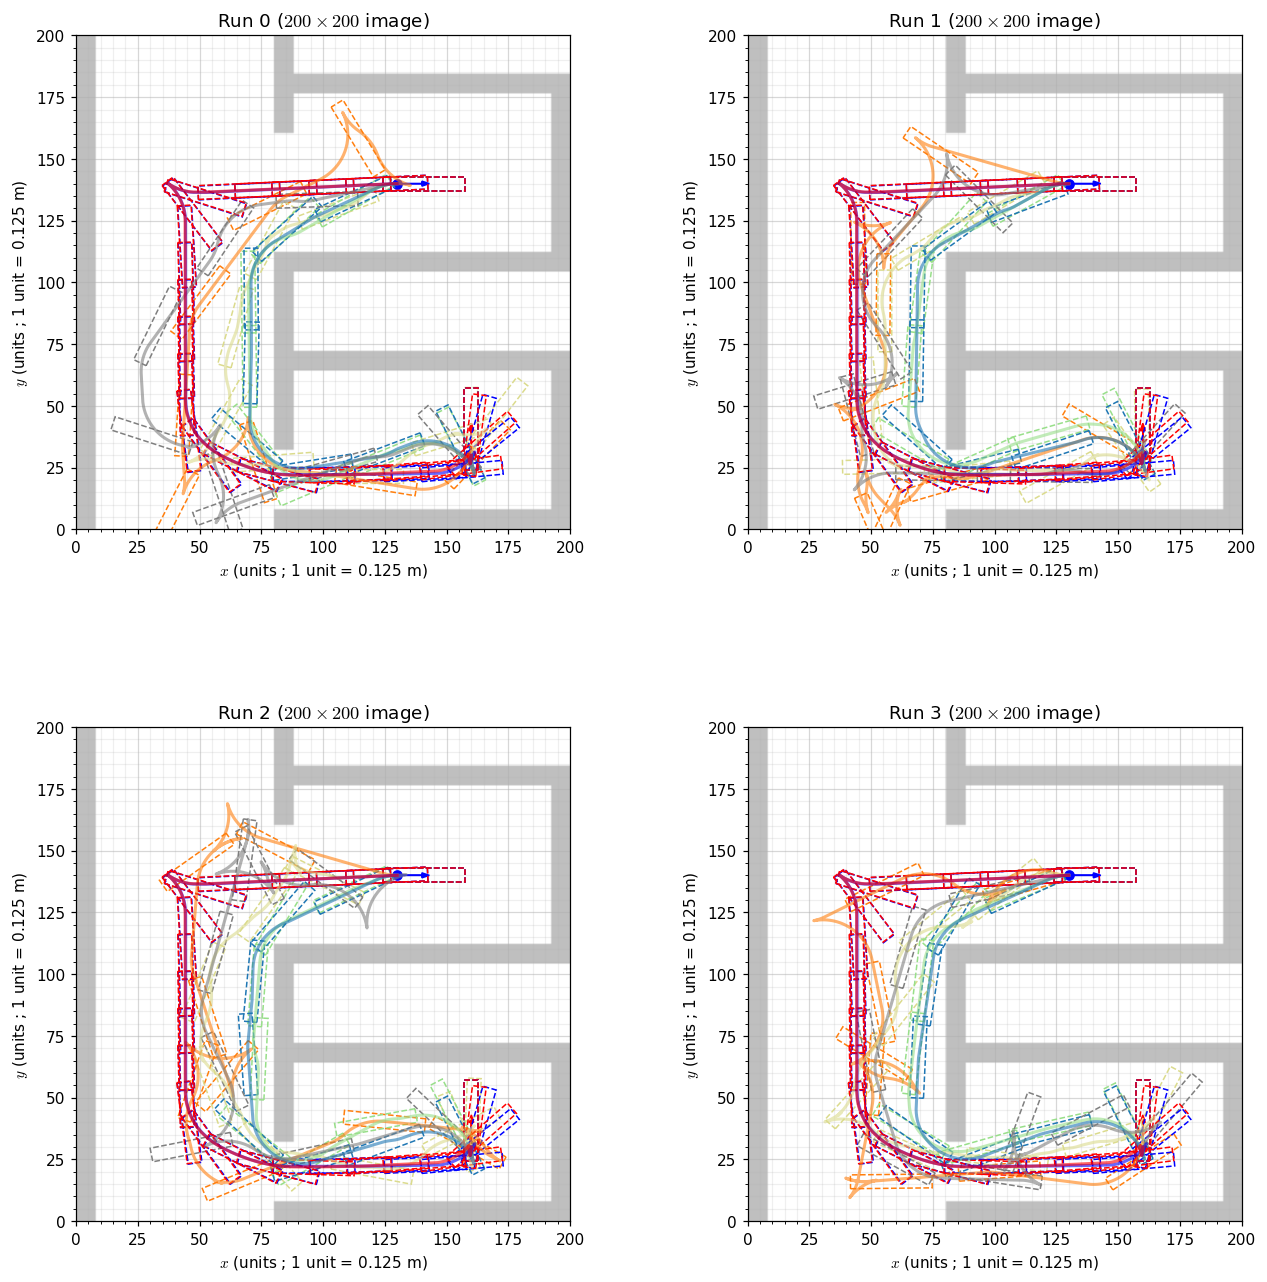

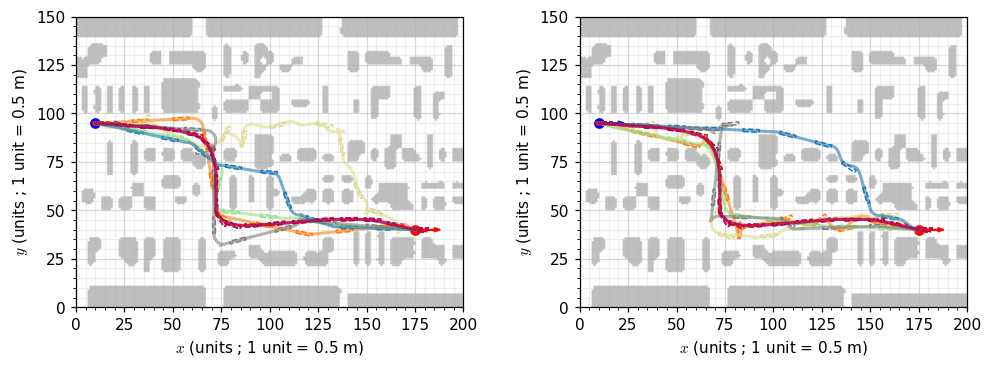

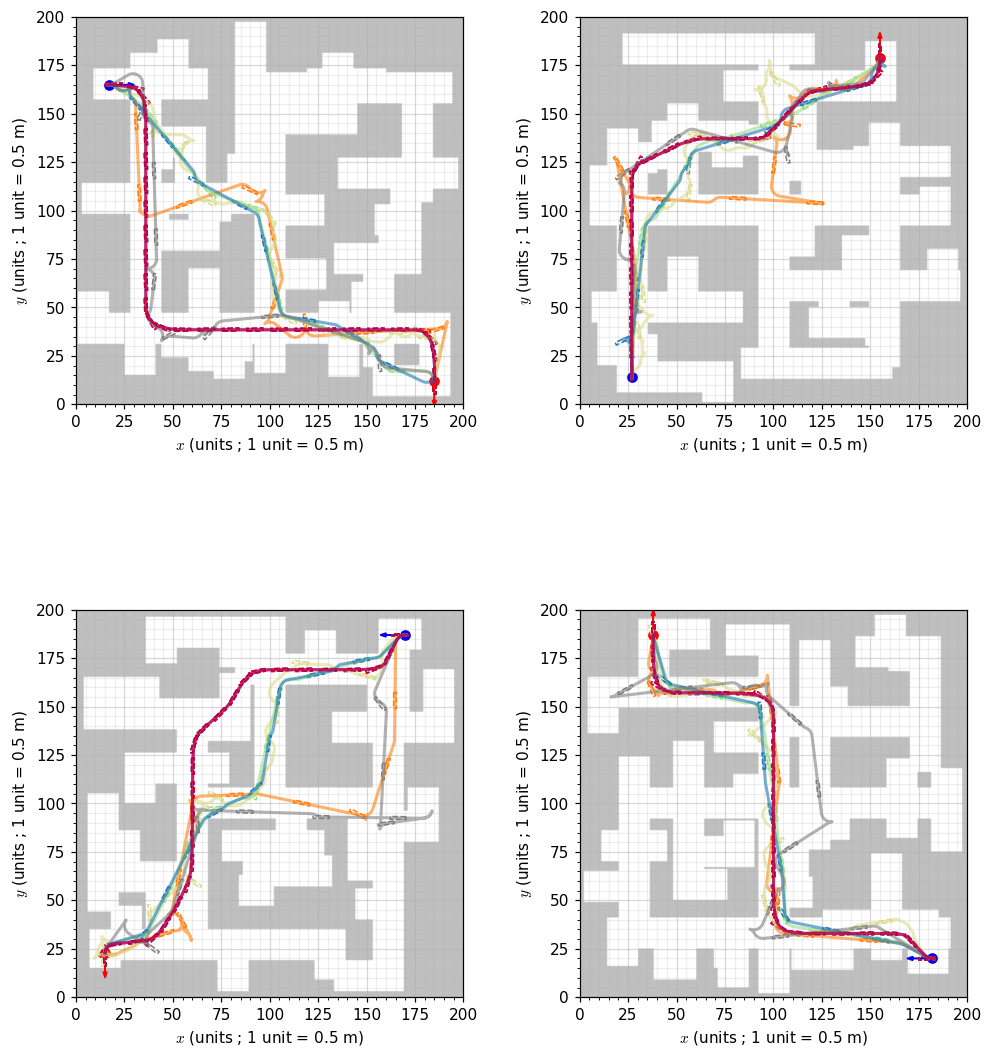

In [5]:
from IPython.display import display

for name, R in RESULTS.items():
    fig = PL.trajectories(R["file"], [R["ours"]["SHFM_2WS"], R["ours"]["SHFM_4WS"]],
                          every_nth=R["every_nth"], run_id=R["run_id"], silence=True,
                          max_plots_per_line=R["per_line"], set_title=R["titles"],
                          fig_width=R["fig_w"], fig_height=R["fig_h"], zoom=R["zoom"],
                          save_file=os.path.join(FIGURE_DIR, "07_%s_traj.pdf" % name))
    display(fig)
    plt.close(fig)

<a id='4'></a>
## 4. Solving again

We solve the Two-Rooms problem five times, 4WS, and measure how far the solves
are from one another, before cleaning, and from the path shipped in
`data/comparison/campaigns/`, which `scripts/acquire_comparison.py` solved with
the same settings. We then give the run-to-run spread of the sampling planners
on the same scene.

In [6]:
from shfm.metrics import path_length

R = RESULTS["two_rooms"]
run = R["data"]["runs"][0]
start, goal = B.endpoints_of(run)
env = from_benchmark_run(run, zoom=R["zoom"], n_theta=100, vehicle=DEFAULT_VEHICLE)
repeats = [solve(env, start, goal, "SHFM_4WS") for _ in range(5)]
shipped = np.load(os.path.join("..", "data", "comparison", "campaigns", "paths.npz"))[
    "two_rooms__run00__4WS"]


def gap(a, b):
    "Largest difference of position (units) and of heading (rad) between two paths."
    if a.shape != b.shape:
        return None
    dtheta = np.angle(np.exp(1j * (a[:, 2] - b[:, 2])))
    return float(np.abs(a[:, :2] - b[:, :2]).max()), float(np.abs(dtheta).max())


print("points per solve :", sorted({len(r) for r in repeats}), "  shipped :", len(shipped))
for label, other in [("solve %d" % i, r) for i, r in enumerate(repeats[1:], 1)] + [("shipped", shipped)]:
    g = gap(repeats[0], np.asarray(other, dtype=float))
    print("  %-9s" % label + ("different number of points" if g is None else
          "largest gap %.1e units (%.1e m), %.1e rad" % (g[0], g[0] / R["zoom"], g[1])))
print("same modes in every solve :", all(np.array_equal(np.rint(r[:, 3]), np.rint(repeats[0][:, 3]))
                                         for r in repeats if len(r) == len(repeats[0])))

lengths = {}
for run in R["data"]["runs"]:
    for planner, plan in run["plans"].items():
        if plan and B.reached_goal(plan):
            lengths.setdefault(planner, []).append(plan["stats"]["path_length"])
lengths["SHFM_4WS"] = [path_length(r[:, :3]) for r in repeats]
print("\nrun-to-run spread in path length, same scene:")
for planner in sorted(lengths):
    v = lengths[planner]
    print("  %-17s %8.2f +/- %.2f   (%d runs)" % (planner, np.mean(v), np.std(v), len(v)))

points per solve : [1392]   shipped : 1392
  solve 1  largest gap 1.5e-05 units (1.9e-06 m), 3.7e-07 rad
  solve 2  largest gap 5.7e-06 units (7.2e-07 m), 3.7e-07 rad
  solve 3  largest gap 1.5e-05 units (1.9e-06 m), 4.8e-07 rad
  solve 4  largest gap 1.5e-05 units (1.9e-06 m), 3.7e-07 rad
  shipped  largest gap 1.5e-05 units (1.9e-06 m), 4.2e-07 rad
same modes in every solve : True

run-to-run spread in path length, same scene:
  InformedRRTstar     247.65 +/- 1.31   (20 runs)
  RRT                 429.40 +/- 87.84   (20 runs)
  RRTstar             248.82 +/- 1.79   (20 runs)
  SHFM_4WS            323.19 +/- 0.00   (5 runs)
  SPARS               401.61 +/- 51.74   (20 runs)
  SST                 329.73 +/- 28.63   (10 runs)


The solver has no random component; two solves of one problem are expected to
agree to within its convergence tolerance, not bit for bit. Here the five
solves, and the shipped path, agree to within a few 1e-5 units, a few
micrometres at this scale. The differences come from the order in which
the GPU updates the blocks of the grid, which changes the last digits of a
single-precision solve.

The sampling planners vary between runs by one or two cells in length for RRT*
and Informed-RRT*, and by tens of cells for RRT, SPARS and SST, because each run
grows a different tree. That is why their runs are shipped rather than re-run.

<a id='5'></a>
## 5. What notebook 8 picks up

The statistics of our own paths, so the metric plates can be drawn without
solving again.

In [7]:
for name, R in RESULTS.items():
    PL.save_stats(R["stats"], os.path.join(STATS_DIR, "stats_%s.json" % name))
print("written to", os.path.relpath(STATS_DIR))

written to ../runs


---

Previous: [6. Discretisation and parameters](06_parameter_study.ipynb)
Next: [8. Benchmark metrics](08_benchmark_metrics.ipynb)